<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session06_regularization_and_normalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۶: منظم‌سازی و نرمال‌سازی: Dropout، Weight Decay، BatchNorm و Data Augmentation

### اهداف این جلسه

- ایجاد عمدی Overfitting و شناخت نشانه‌های آن در منحنی‌های آموزش
- درک و پیاده‌سازی Weight Decay، Dropout و Early Stopping
- پیاده‌سازی Batch Normalization از صفر و مقایسه با `nn.BatchNorm1d`؛ آشنایی با LayerNorm
- افزایش داده (Data Augmentation) با `torchvision.transforms`
- مقایسه منصفانه همه روش‌ها در یک آزمایش کنترل‌شده

> **نکتهٔ اجرا:** این نوت‌بوک روی GPU بسیار سریع‌تر اجرا می‌شود. در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. Overfitting در شبکه‌های عصبی

شبکه‌های عصبی ظرفیت بسیار زیادی دارند: MLP جلسه ۴ بیش از ۲۳۵ هزار پارامتر داشت. با داده کم، چنین مدلی می‌تواند داده آموزشی را **حفظ** کند به‌جای اینکه الگوی کلی را **یاد بگیرد**. در جلسه ۴ نشانه آن را دیدیم: Loss آموزش پیوسته کم می‌شد اما Loss اعتبارسنجی بعد از چند Epoch بالا رفت.

**منظم‌سازی (Regularization)** به هر تکنیکی گفته می‌شود که خطای تعمیم (Generalization Error) را کاهش دهد، حتی اگر خطای آموزش کمی بیشتر شود. برای اینکه اثر هر روش به‌وضوح دیده شود، یک **آزمایش کنترل‌شده** طراحی می‌کنیم: فقط ۵٬۰۰۰ تصویر از داده آموزشی Fashion-MNIST، یک MLP بزرگ و آموزش طولانی. در این شرایط Overfitting شدید است.

</div>

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(42)
np.random.seed(42)

device: cpu


In [2]:
MEAN, STD = 0.2860, 0.3530
base_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

full_train = datasets.FashionMNIST('data', train=True, download=True, transform=base_tf)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=base_tf)

perm = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(42))
small_idx, val_idx = perm[:5_000], perm[50_000:]          # 5,000 training images, 10,000 for validation
small_train = Subset(full_train, small_idx)
val_set = Subset(full_train, val_idx)

small_loader = DataLoader(small_train, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=1000, num_workers=2)
print('small training set:', len(small_train), '| validation:', len(val_set))

small training set: 5000 | validation: 10000


In [3]:
def train_one_epoch(model, loader, criterion, optimizer, device, scheduler=None):
    """One pass over the training data. `scheduler` is stepped after every batch if given."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, optimizer, epochs, device, scheduler=None, verbose=True):
    """Train for `epochs` epochs and return the history of losses and accuracies."""
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(1, epochs + 1):
        tr = train_one_epoch(model, train_loader, criterion, optimizer, device, scheduler)
        va = evaluate(model, val_loader, criterion, device)
        for k, v in zip(history, (*tr, *va)):
            history[k].append(v)
        if verbose:
            print(f'epoch {epoch:2d} | train loss {tr[0]:.4f} acc {tr[1]:.4f} | val loss {va[0]:.4f} acc {va[1]:.4f}')
    return history

In [4]:
def make_mlp(hidden=1024, depth=3, dropout=0.0, batchnorm=False):
    """A deliberately large MLP; dropout and batch norm can be switched on."""
    layers, n_in = [nn.Flatten()], 784
    for _ in range(depth):
        layers.append(nn.Linear(n_in, hidden))
        if batchnorm:
            layers.append(nn.BatchNorm1d(hidden))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        n_in = hidden
    layers.append(nn.Linear(n_in, 10))
    return nn.Sequential(*layers)


def plot_curves(histories, key='val_loss', title='validation loss'):
    plt.figure(figsize=(9, 4))
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel('epoch'); plt.title(title); plt.legend(); plt.show()


EPOCHS = 40
histories = {}
torch.manual_seed(0)
model = make_mlp().to(device)
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}  for {len(small_train):,} training images')
histories['baseline'] = fit(model, small_loader, val_loader, torch.optim.Adam(model.parameters(), lr=1e-3), EPOCHS, device, verbose=False)
h = histories['baseline']
print(f"final: train acc {h['train_acc'][-1]:.3f} | val acc {h['val_acc'][-1]:.3f} | best val loss {min(h['val_loss']):.3f} at epoch {np.argmin(h['val_loss']) + 1}")

parameters: 2,913,290  for 5,000 training images


final: train acc 0.979 | val acc 0.844 | best val loss 0.445 at epoch 4


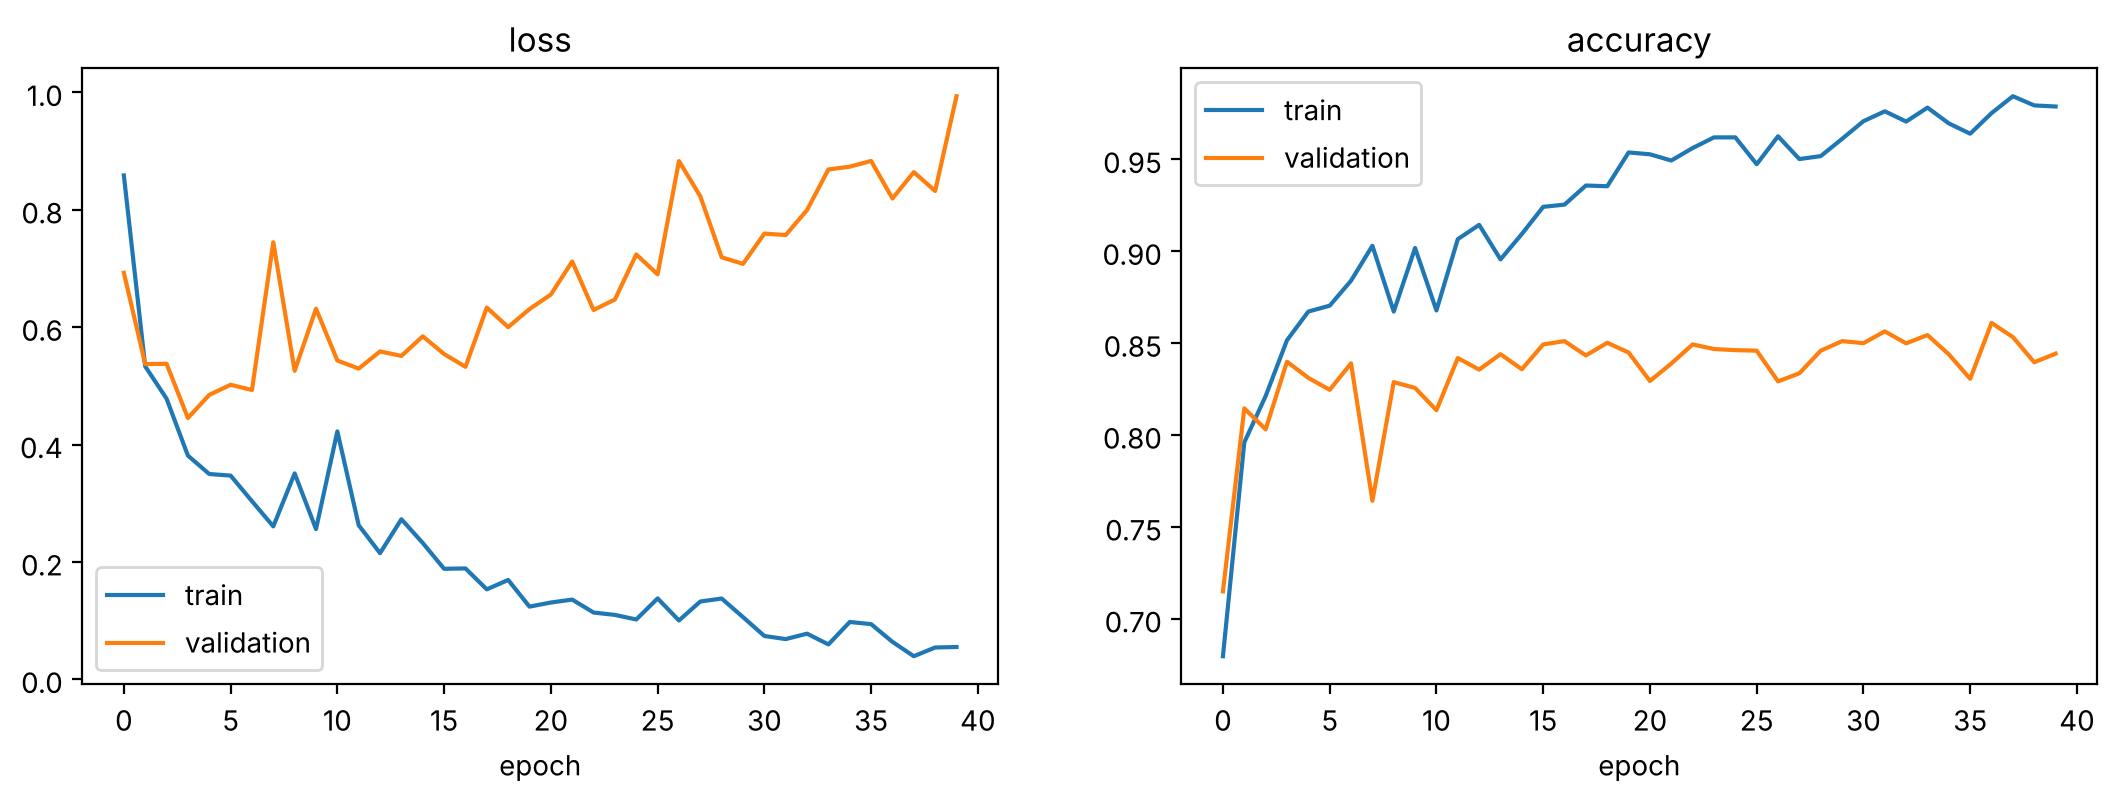

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(h['train_loss'], label='train'); axes[0].plot(h['val_loss'], label='validation'); axes[0].set_title('loss')
axes[1].plot(h['train_acc'], label='train'); axes[1].plot(h['val_acc'], label='validation'); axes[1].set_title('accuracy')
for ax in axes:
    ax.set_xlabel('epoch'); ax.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

دقت آموزش به حدود ۹۸٪ می‌رسد، اما Loss اعتبارسنجی پس از کمینه شدن در حدود Epoch چهارم **مدام افزایش** می‌یابد: مدل روی نمونه‌هایی که اشتباه می‌کند بیش از حد مطمئن شده است. حالا ابزارهای منظم‌سازی را یکی‌یکی امتحان می‌کنیم.

## ۲. Weight Decay (منظم‌سازی L2)

ایده: وزن‌های بزرگ را جریمه کنیم تا مدل ساده‌تر و هموارتر بماند. به تابع هزینه یک جمله اضافه می‌کنیم:

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{data}} + \frac{\lambda}{2}\sum_i w_i^2$$

گرادیان این جمله $\lambda w$ است؛ پس در هر گام SGD وزن‌ها کمی به سمت صفر «فرو می‌ریزند» (Decay):

$$w \leftarrow w - \eta\left(\nabla\mathcal{L}_{\text{data}} + \lambda w\right) = (1 - \eta\lambda)\,w - \eta\nabla\mathcal{L}_{\text{data}}$$

این همان Ridge Regression دوره یادگیری ماشین است. در PyTorch کافی است آرگومان `weight_decay` را به Optimizer بدهیم. همان‌طور که در جلسه ۵ دیدیم، برای Adam بهتر است از **AdamW** استفاده کنیم که کاهش وزن را جدا از گرادیان اعمال می‌کند.

</div>

In [6]:
torch.manual_seed(0)
model = make_mlp().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.1)
histories['weight decay'] = fit(model, small_loader, val_loader, opt, EPOCHS, device, verbose=False)
print(f"weight decay: val acc {histories['weight decay']['val_acc'][-1]:.3f} | best val loss {min(histories['weight decay']['val_loss']):.3f}")

weight decay: val acc 0.837 | best val loss 0.459


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. Dropout

**Dropout** (Srivastava et al., 2014) در هر گام آموزش، هر نورون را با احتمال $p$ به‌طور تصادفی **خاموش** (صفر) می‌کند. در نتیجه:

- هیچ نورونی نمی‌تواند به حضور نورون‌های خاص دیگر وابسته شود (کاهش **Co-adaptation**)؛ هر نورون باید ویژگی‌ای مستقلاً مفید یاد بگیرد.
- هر Batch در واقع یک «زیرشبکه» متفاوت را آموزش می‌دهد و مدل نهایی مثل **میانگین گروهی (Ensemble)** از تعداد بسیار زیادی زیرشبکه عمل می‌کند.

در زمان آزمون Dropout خاموش است. برای اینکه مقدار مورد انتظار خروجی در آموزش و آزمون یکسان باشد، در زمان آموزش خروجی نورون‌های فعال را بر $(1-p)$ تقسیم می‌کنیم (**Inverted Dropout**). پیاده‌سازی از صفر:

</div>

In [7]:
class MyDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.p = p

    def forward(self, x):
        if not self.training or self.p == 0:      # identity at evaluation time
            return x
        mask = (torch.rand_like(x) > self.p).float()
        return x * mask / (1 - self.p)           # inverted dropout keeps the expected value unchanged


drop = MyDropout(p=0.5)
x = torch.ones(2, 10)
drop.train(); print('train mode:\n', drop(x))
drop.eval();  print('eval mode:\n', drop(x))

big = torch.ones(1000, 1000)
drop.train(); print('mean in train mode (should be ~1):', drop(big).mean().item())

train mode:
 tensor([[0., 0., 0., 2., 2., 0., 0., 2., 2., 2.],
        [2., 2., 2., 0., 0., 2., 0., 0., 0., 2.]])
eval mode:
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])
mean in train mode (should be ~1): 0.9993199706077576


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

این دقیقاً رفتار `nn.Dropout` است و به همین دلیل `model.train()` و `model.eval()` اهمیت دارند: فراموش کردن `model.eval()` هنگام ارزیابی باعث می‌شود پیش‌بینی‌ها تصادفی و ضعیف شوند. مقادیر رایج $p$: بین $0.1$ و $0.5$ برای لایه‌های Fully Connected.

</div>

In [8]:
torch.manual_seed(0)
model = make_mlp(dropout=0.5).to(device)
histories['dropout 0.5'] = fit(model, small_loader, val_loader, torch.optim.Adam(model.parameters(), lr=1e-3), EPOCHS, device, verbose=False)
print(f"dropout: val acc {histories['dropout 0.5']['val_acc'][-1]:.3f} | best val loss {min(histories['dropout 0.5']['val_loss']):.3f}")

dropout: val acc 0.851 | best val loss 0.444


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. Batch Normalization

در جلسه ۴ ورودی شبکه را نرمال کردیم تا آموزش پایدارتر شود. **Batch Normalization** (Ioffe & Szegedy, 2015) همین کار را برای ورودی **هر لایه** انجام می‌دهد. برای یک Mini-batch با مقادیر $x_1, \dots, x_m$ (برای هر ویژگی جداگانه):

$$\mu_B = \frac{1}{m}\sum_{i} x_i,\qquad \sigma_B^2 = \frac{1}{m}\sum_{i}(x_i-\mu_B)^2,\qquad \hat{x}_i = \frac{x_i-\mu_B}{\sqrt{\sigma_B^2+\epsilon}},\qquad y_i = \gamma\,\hat{x}_i + \beta$$

پارامترهای قابل آموزش $\gamma$ و $\beta$ به شبکه اجازه می‌دهند در صورت نیاز توزیع دلخواهی را بازسازی کند.

**تفاوت آموزش و آزمون:** در آموزش از آمار همان Batch استفاده می‌شود، اما در آزمون ممکن است فقط یک نمونه داشته باشیم. پس در طول آموزش یک **میانگین متحرک (Running Mean/Variance)** از آمار Batchها نگه می‌داریم و در حالت `eval` از آن استفاده می‌کنیم.

فواید BatchNorm: امکان نرخ یادگیری بزرگ‌تر، همگرایی بسیار سریع‌تر، حساسیت کمتر به مقداردهی اولیه و کمی اثر منظم‌سازی (به دلیل نویز آمار Batch). پیاده‌سازی از صفر و مقایسه با PyTorch:

</div>

In [9]:
class MyBatchNorm1d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.gamma = nn.Parameter(torch.ones(num_features))
        self.beta = nn.Parameter(torch.zeros(num_features))
        # buffers: saved in state_dict and moved by .to(device), but not trained
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))

    def forward(self, x):
        if self.training:
            mean = x.mean(dim=0)
            var = x.var(dim=0, unbiased=False)
            with torch.no_grad():
                n = x.shape[0]
                self.running_mean.lerp_(mean, self.momentum)
                self.running_var.lerp_(var * n / (n - 1), self.momentum)   # PyTorch stores the unbiased variance
        else:
            mean, var = self.running_mean, self.running_var
        x_hat = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * x_hat + self.beta


torch.manual_seed(0)
mine, ref = MyBatchNorm1d(4), nn.BatchNorm1d(4)
for _ in range(5):                                   # a few training steps update the running statistics
    batch = torch.randn(32, 4) * 3 + 2
    out_mine, out_ref = mine(batch), ref(batch)
print('train-mode outputs match:', torch.allclose(out_mine, out_ref, atol=1e-5))
mine.eval(); ref.eval()
test_batch = torch.randn(8, 4) * 3 + 2
print('eval-mode outputs match :', torch.allclose(mine(test_batch), ref(test_batch), atol=1e-5))
print('running mean:', ref.running_mean)

train-mode outputs match: True
eval-mode outputs match : True
running mean: tensor([0.8872, 0.9802, 0.9662, 0.7515])


In [10]:
torch.manual_seed(0)
model = make_mlp(batchnorm=True).to(device)
histories['batchnorm'] = fit(model, small_loader, val_loader, torch.optim.Adam(model.parameters(), lr=1e-3), EPOCHS, device, verbose=False)
print(f"batchnorm: val acc {histories['batchnorm']['val_acc'][-1]:.3f} | best val loss {min(histories['batchnorm']['val_loss']):.3f}")

batchnorm: val acc 0.842 | best val loss 0.467


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### اثر BatchNorm روی سرعت آموزش شبکه عمیق

اثر اصلی BatchNorm **پایداری و سرعت بهینه‌سازی** است، نه لزوماً منظم‌سازی. یک MLP عمیق‌تر (۸ لایه) با SGD روی کل داده آموزشی، یک بار با و یک بار بدون BatchNorm، برای ۳ Epoch:

</div>

In [11]:
train_set = Subset(full_train, perm[:50_000])
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
deep = {}
for bn in (False, True):
    torch.manual_seed(0)
    m = make_mlp(hidden=256, depth=8, batchnorm=bn).to(device)
    name = 'with BatchNorm' if bn else 'without BatchNorm'
    deep[name] = fit(m, train_loader, val_loader, torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9), 3, device, verbose=False)
    print(f"{name:18s}: val acc per epoch {np.round(deep[name]['val_acc'], 3)}")

without BatchNorm : val acc per epoch [0.601 0.807 0.852]


with BatchNorm    : val acc per epoch [0.849 0.866 0.872]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### LayerNorm

BatchNorm به اندازه Batch وابسته است: با Batchهای خیلی کوچک آمار آن نویزی می‌شود و برای داده‌های دنباله‌ای با طول متغیر (متن) مناسب نیست. **Layer Normalization** (Ba et al., 2016) نرمال‌سازی را روی **ویژگی‌های هر نمونه** انجام می‌دهد، نه روی نمونه‌های یک Batch؛ پس رفتارش در آموزش و آزمون یکسان است. LayerNorm جزء اصلی Transformerهاست (جلسه ۱۳).

| | BatchNorm | LayerNorm |
|---|---|---|
| نرمال‌سازی روی | نمونه‌های Batch (برای هر ویژگی) | ویژگی‌ها (برای هر نمونه) |
| رفتار Train و Eval | متفاوت (Running Stats) | یکسان |
| کاربرد اصلی | CNNها | Transformerها و RNNها |

## ۵. Early Stopping

ساده‌ترین و پرکاربردترین منظم‌سازی: آموزش را وقتی Loss اعتبارسنجی برای چند Epoch متوالی (**Patience**) بهتر نشد متوقف می‌کنیم و **بهترین مدل** را برمی‌گردانیم.

</div>

In [12]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss, self.best_state, self.counter = float('inf'), None, 0

    def step(self, val_loss, model):
        """Returns True when training should stop."""
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss, self.counter = val_loss, 0
            self.best_state = copy.deepcopy(model.state_dict())   # keep the best weights
        else:
            self.counter += 1
        return self.counter >= self.patience


torch.manual_seed(0)
model = make_mlp().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
stopper = EarlyStopping(patience=5)
for epoch in range(1, EPOCHS + 1):
    train_one_epoch(model, small_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    if stopper.step(val_loss, model):
        print(f'stopped at epoch {epoch}; best val loss {stopper.best_loss:.4f}')
        break
model.load_state_dict(stopper.best_state)
print('restored best model -> val acc', round(evaluate(model, val_loader, criterion, device)[1], 4))

stopped at epoch 9; best val loss 0.4453


restored best model -> val acc 0.8399


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. افزایش داده (Data Augmentation)

بهترین درمان Overfitting **داده بیشتر** است. وقتی داده بیشتری نداریم، می‌توانیم از هر تصویر نسخه‌های تغییریافته‌ای بسازیم که برچسب را عوض نمی‌کنند: قرینه افقی، جابه‌جایی کوچک، چرخش جزئی، تغییر مقیاس و … . این تغییرات **در هر Epoch به‌صورت تصادفی** و فقط روی داده **آموزشی** اعمال می‌شوند.

انتخاب تبدیل‌ها باید با دانش مسئله باشد: قرینه افقی یک کفش هنوز کفش است، اما قرینه عدد ۶ در MNIST ممکن است شبیه چیز دیگری شود و چرخش ۱۸۰ درجه آن، ۹ است!

</div>

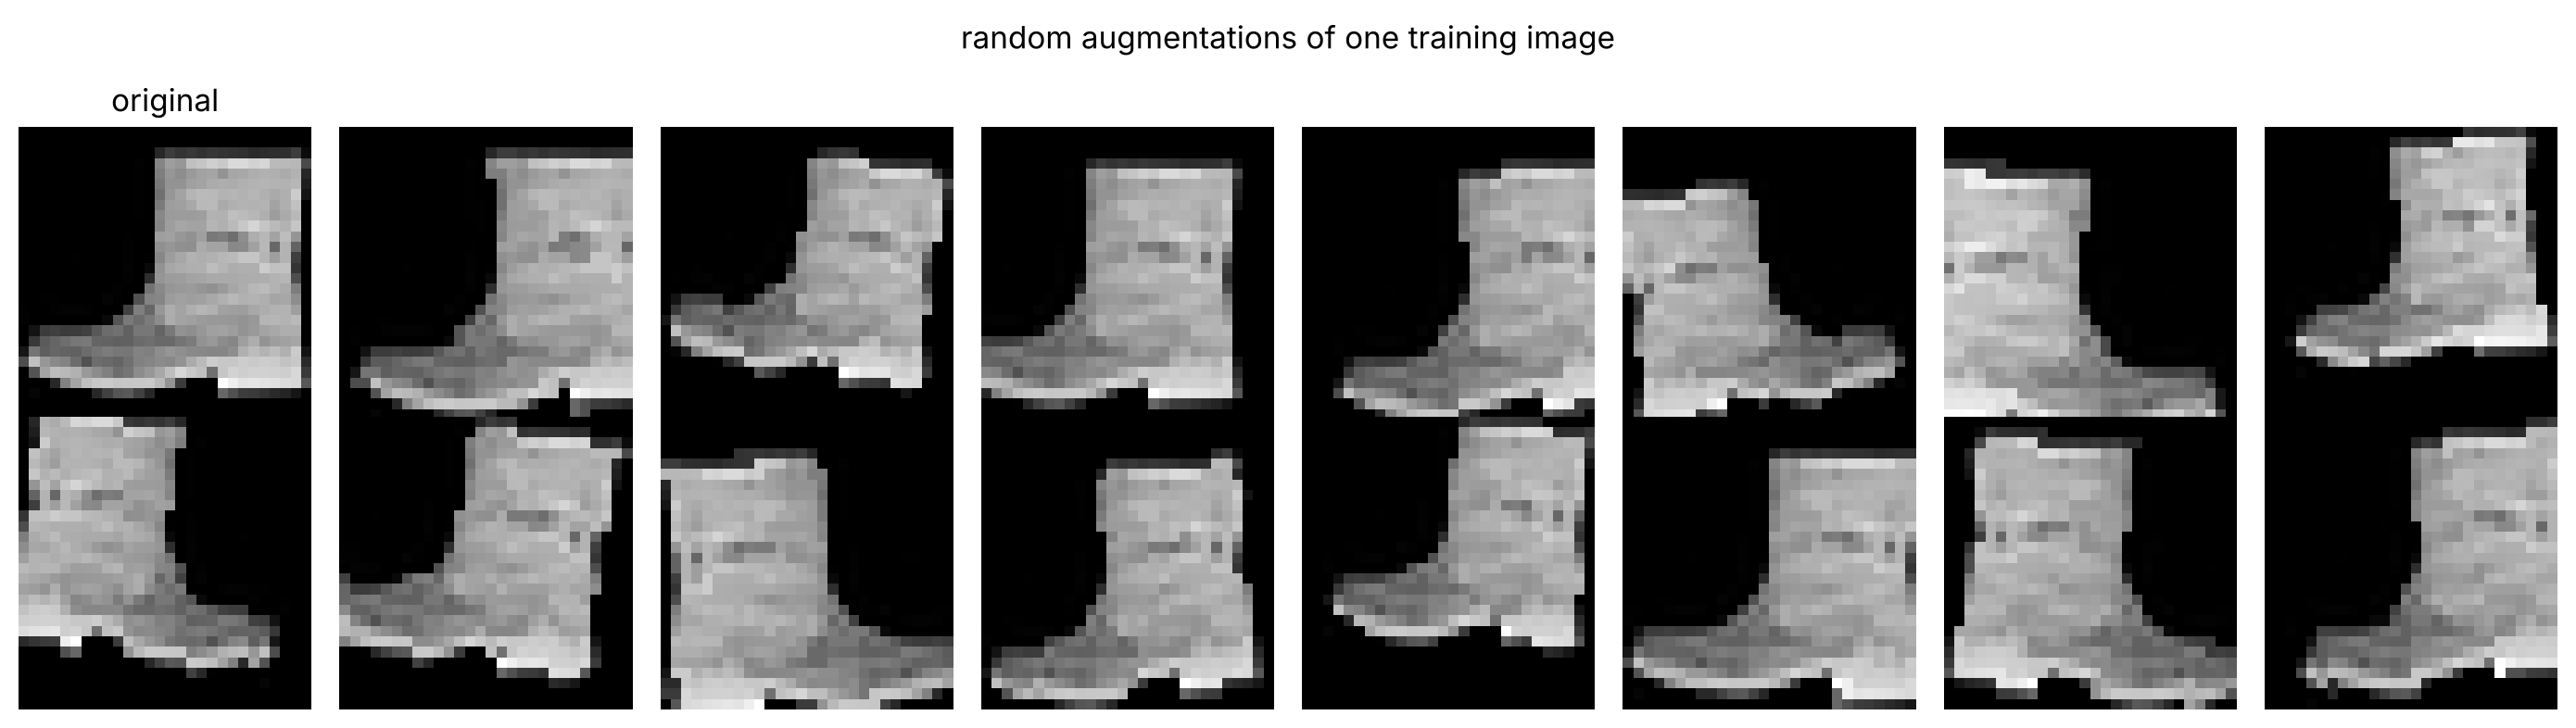

In [13]:
aug_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])
aug_full = datasets.FashionMNIST('data', train=True, download=True, transform=aug_tf)
aug_train = Subset(aug_full, small_idx)                       # same 5,000 images, random augmentation each epoch
aug_loader = DataLoader(aug_train, batch_size=128, shuffle=True, num_workers=2)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
raw = datasets.FashionMNIST('data', train=True, download=True)
img, _ = raw[int(small_idx[0])]
axes[0, 0].imshow(img, cmap='gray'); axes[0, 0].set_title('original')
for ax in list(axes.flat)[1:]:
    ax.imshow(aug_tf.transforms[1](aug_tf.transforms[0](img)), cmap='gray')
for ax in axes.flat:
    ax.axis('off')
plt.suptitle('random augmentations of one training image'); plt.tight_layout(); plt.show()

In [14]:
torch.manual_seed(0)
model = make_mlp().to(device)
histories['augmentation'] = fit(model, aug_loader, val_loader, torch.optim.Adam(model.parameters(), lr=1e-3), EPOCHS, device, verbose=False)
print(f"augmentation: val acc {histories['augmentation']['val_acc'][-1]:.3f} | best val loss {min(histories['augmentation']['val_loss']):.3f}")

augmentation: val acc 0.817 | best val loss 0.493


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. ترکیب روش‌ها و مقایسه نهایی

در عمل این روش‌ها با هم استفاده می‌شوند. یک مدل با ترکیب BatchNorm، Dropout، AdamW با Weight Decay و Augmentation آموزش می‌دهیم و همه را مقایسه می‌کنیم:

</div>

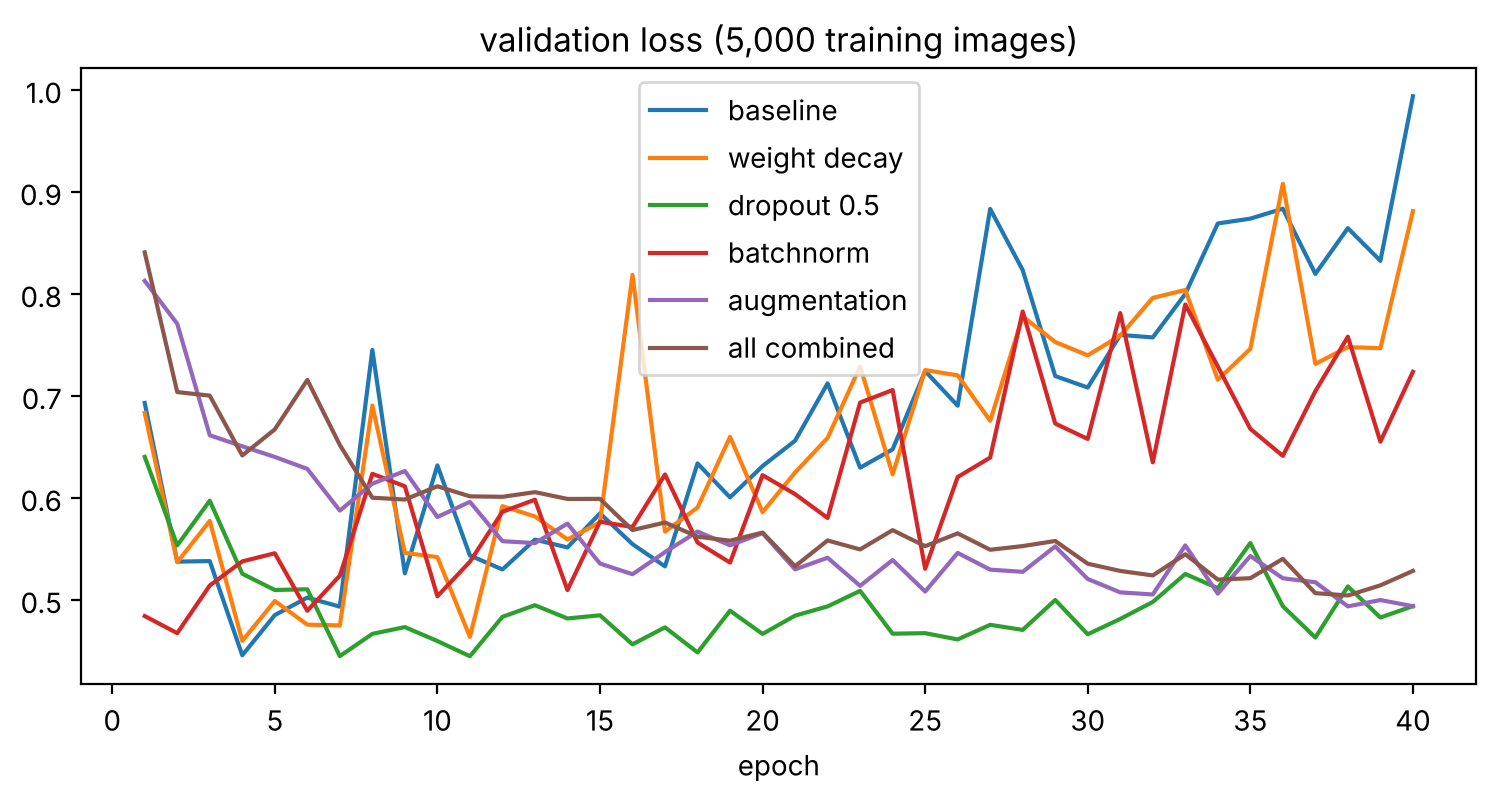

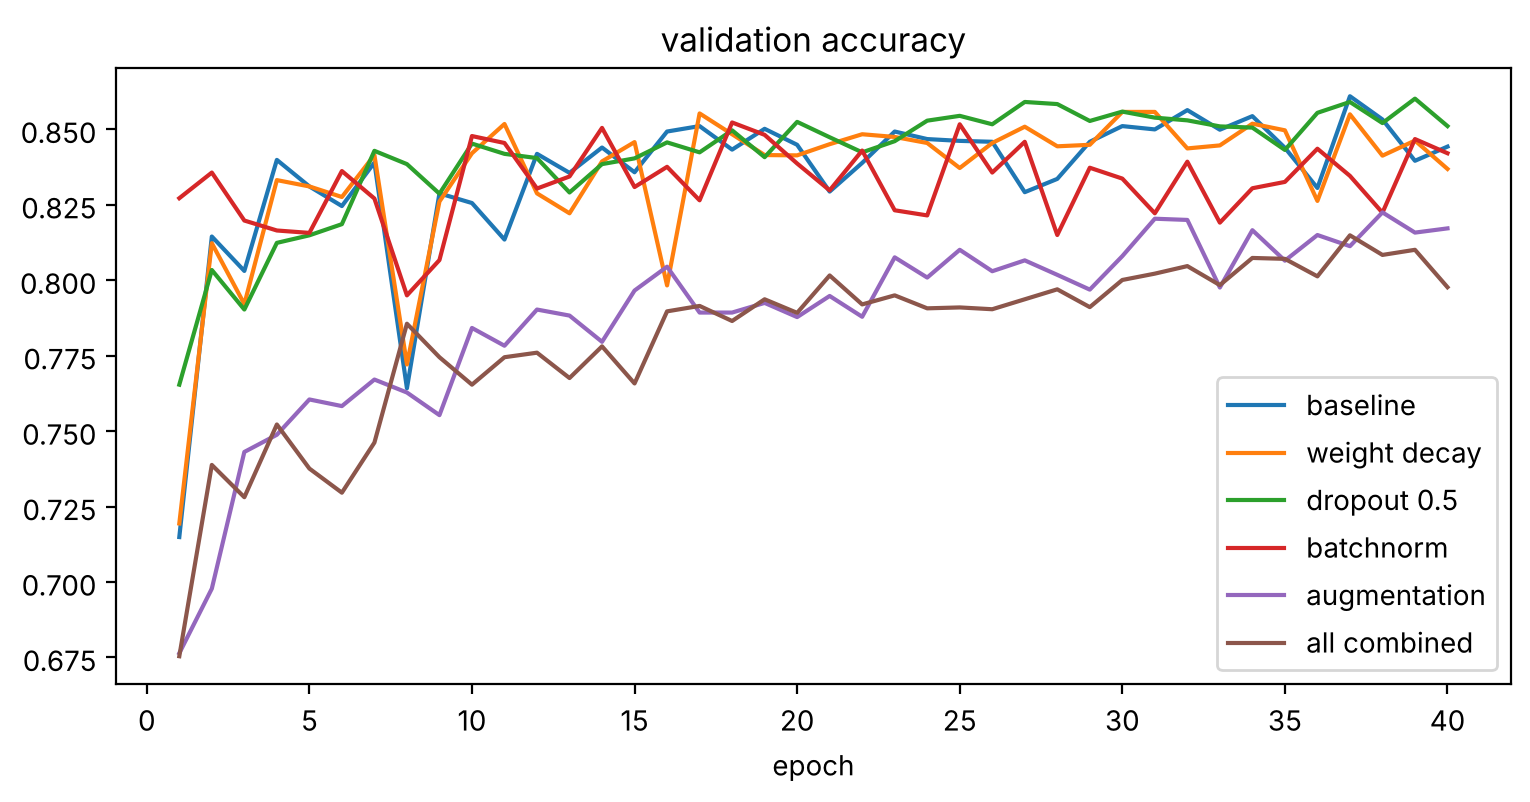

method           final train acc  final val acc  best val acc     gap
baseline                   0.979          0.844         0.861   0.134
weight decay               0.982          0.837         0.856   0.145
dropout 0.5                0.891          0.851         0.860   0.040
batchnorm                  0.972          0.842         0.852   0.130
augmentation               0.794          0.817         0.823  -0.023
all combined               0.755          0.798         0.815  -0.043


In [15]:
torch.manual_seed(0)
model = make_mlp(dropout=0.3, batchnorm=True).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
histories['all combined'] = fit(model, aug_loader, val_loader, opt, EPOCHS, device, verbose=False)

plot_curves(histories, 'val_loss', 'validation loss (5,000 training images)')
plot_curves(histories, 'val_acc', 'validation accuracy')

print(f"{'method':15s} {'final train acc':>16s} {'final val acc':>14s} {'best val acc':>13s} {'gap':>7s}")
for name, h in histories.items():
    gap = h['train_acc'][-1] - h['val_acc'][-1]
    print(f"{name:15s} {h['train_acc'][-1]:16.3f} {h['val_acc'][-1]:14.3f} {max(h['val_acc']):13.3f} {gap:7.3f}")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تحلیل:** ستون `gap` (فاصله دقت آموزش و اعتبارسنجی) معیار مستقیم Overfitting است. نتایج این آزمایش چند درس مهم دارد:

- در **Baseline**، **Weight Decay** و **BatchNorm**، Loss اعتبارسنجی بعد از چند Epoch به‌شدت بالا می‌رود و فاصله دقت حدود ۱۳ تا ۱۵ درصد است. Weight Decay با این مقدار اثر کمی داشت و BatchNorm اساساً ابزار منظم‌سازی نیست؛ مزیت اصلی آن سرعت و پایداری آموزش است (آزمایش بخش ۴).
- **Dropout** در این آزمایش بهترین تعادل را داشت: Loss اعتبارسنجی پایدار ماند و فاصله دقت به حدود ۴٪ رسید.
- **Augmentation** و **ترکیب همه روش‌ها** Overfitting را کاملاً حذف کردند (فاصله منفی، چون دقت آموزش روی تصاویر تغییریافته که سخت‌ترند سنجیده می‌شود)، اما منحنی‌ها نشان می‌دهند هنوز در حال یادگیری‌اند و ۴۰ Epoch برایشان کافی نیست. **منظم‌سازی قوی‌تر معمولاً آموزش طولانی‌تر لازم دارد.**

نتیجه کلی: هیچ روشی همیشه بهترین نیست؛ اثر هر روش به داده، مدل و ابرپارامترها بستگی دارد و این انتخاب‌ها همیشه باید با داده **اعتبارسنجی** انجام شوند.

## جمع‌بندی

- Overfitting یعنی فاصله زیاد بین عملکرد آموزش و اعتبارسنجی؛ با داده کم و مدل بزرگ شدید می‌شود.
- **Weight Decay:** جریمه L2 روی وزن‌ها؛ در PyTorch با `weight_decay` (برای Adam از AdamW استفاده کنید).
- **Dropout:** خاموش کردن تصادفی نورون‌ها در آموزش؛ در `eval` غیرفعال است.
- **BatchNorm:** نرمال‌سازی ورودی هر لایه با آمار Batch؛ سرعت و پایداری آموزش را بسیار بالا می‌برد. **LayerNorm** جایگزین آن در Transformerهاست.
- **Early Stopping:** توقف وقتی Loss اعتبارسنجی بهتر نمی‌شود و بازگرداندن بهترین مدل.
- **Data Augmentation:** ساخت نسخه‌های تغییریافته تصادفی از داده آموزشی؛ بسیار مؤثر به‌ویژه برای CNNها، اما به آموزش طولانی‌تر نیاز دارد.
- `model.train()` و `model.eval()` به‌خاطر Dropout و BatchNorm حیاتی‌اند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. آزمایش Dropout را با $p \in \{0.1, 0.3, 0.5, 0.7\}$ تکرار کنید و بهترین دقت اعتبارسنجی را بر حسب $p$ رسم کنید.

۲. Weight Decay را با $\lambda \in \{0.001, 0.01, 0.1, 1\}$ امتحان کنید. با $\lambda$ خیلی بزرگ چه اتفاقی می‌افتد (Underfitting)؟

۳. در مدل `batchnorm`، بعد از آموزش یک بار ارزیابی را **بدون** `model.eval()` انجام دهید (مدل در حالت train بماند) و با Batchهای اندازه ۲ پیش‌بینی کنید. چرا دقت افت می‌کند؟

۴. `nn.LayerNorm` را جایگزین `nn.BatchNorm1d` در `make_mlp` کنید و نتایج دو آزمایش BatchNorm را تکرار کنید.

۵. مدل‌های `augmentation` و `all combined` را ۱۵۰ Epoch آموزش دهید. آیا در نهایت از Dropout بهتر می‌شوند؟

۶. آزمایش مقایسه نهایی را با ۵۰٬۰۰۰ تصویر آموزشی تکرار کنید. آیا تفاوت روش‌ها کمتر می‌شود؟ چرا؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** آزمایش Dropout را با $p \in \{0.1, 0.3, 0.5, 0.7\}$ تکرار کنید و بهترین دقت اعتبارسنجی را بر حسب $p$ رسم کنید.

</div>

In [16]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** Weight Decay را با $\lambda \in \{0.001, 0.01, 0.1, 1\}$ امتحان کنید. با $\lambda$ خیلی بزرگ چه اتفاقی می‌افتد (Underfitting)؟

</div>

In [17]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** در مدل `batchnorm`، بعد از آموزش یک بار ارزیابی را **بدون** `model.eval()` انجام دهید (مدل در حالت train بماند) و با Batchهای اندازه ۲ پیش‌بینی کنید. چرا دقت افت می‌کند؟

</div>

In [18]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** `nn.LayerNorm` را جایگزین `nn.BatchNorm1d` در `make_mlp` کنید و نتایج دو آزمایش BatchNorm را تکرار کنید.

</div>

In [19]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** مدل‌های `augmentation` و `all combined` را ۱۵۰ Epoch آموزش دهید. آیا در نهایت از Dropout بهتر می‌شوند؟

</div>

In [20]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۶.** آزمایش مقایسه نهایی را با ۵۰٬۰۰۰ تصویر آموزشی تکرار کنید. آیا تفاوت روش‌ها کمتر می‌شود؟ چرا؟

</div>

In [21]:
# پاسخ خود را اینجا بنویسید
